In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


## 1.Data loading and visualization and preprocessing¶

In [2]:
train = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv')
test = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv')
sample = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv')

## **Business Problem Statement**


**Scenario:** I am a Data Scientist at a workspace rental platform. The company offers bookable workspaces across different metropolitan areas, and the price of each listing depends on its location, capacity, facilities, operator characteristics, booking terms, availability, and customer reviews. The business wants to develop a predictive model to classify each workspace into the correct price tier.

**Business Impact:**
- **Pricing Strategy**: Accurate price-tier classification can help the platform understand pricing patterns across different workspace categories and locations

- **Market Segmentation**: Identifying price tiers can help the business segment workspaces according to their market positioning and attributes.

-  **Revenue Optimization**: Understanding the factors associated with different price tiers can support better pricing decisions and improve the use of workspace inventory.

-  **Customer Experience**: Appropriate price positioning can help customers find workspaces that match their requirements and budgets.

-  **Business Growth**: Data-driven insights can help operators understand how workspace capacity, facilities, location, and customer reviews relate to price-tier differences.


**MY Mission**: Build an end-to-end machine learning pipeline that predicts the price tier of each workspace listing using its available attributes. Perform exploratory data analysis (EDA), handle missing values, engineer useful features, compare classification models, and optimize performance using Macro F1-score. The final model should generate accurate price-tier predictions for all listings in the test dataset.

## **1. Project Overview and Data Understanding**

**1.1 Industry Context: Workspace Rental and Pricing**

Workspace rental platforms connect customers with bookable workspaces across different metropolitan areas. Pricing is a critical factor in this industry because workspace value depends on location, capacity, facilities, booking flexibility, availability, and operator characteristics.

Accurate price-tier classification can help platforms understand market positioning, identify pricing patterns, and support data-driven decisions. However, workspace attributes do not always have a direct or consistent relationship with price, as local market conditions and customer requirements can influence pricing.

**Key Business Challenges:**

- **Location-Based Pricing:** Workspace prices may vary across metropolitan areas, and neighbourhoods.
- **Workspace Diversity:** Different property types, access arrangements, seating capacities, and facilities serve different customer needs.
- **Operator Differences:** Operator experience, certification, and portfolio size may be associated with differences in service quality and market positioning.
- **Demand and Availability:** Booking activity, booked load, and remaining availability may provide information about workspace demand.
- **Customer Reviews:** Ratings and review history can help characterize customer satisfaction and listing reputation.
- **Booking Flexibility:** Minimum and maximum booking terms can influence the types of customers a workspace serves.

**1.2 Dataset Overview**
**Source:** Kaggle Workspace Rental Price-Tier Prediction Competition

**Business Context:** Workspace listing data containing information about locations, physical attributes, operators, facilities, booking terms, availability, and customer reviews.

**Prediction Target:** Which price tier does a workspace listing belong to? (Multiclass classification using the price_tier variable.)

**Dataset Files**
- **train.csv:** Contains workspace attributes and the target variable price_tier.
- **test.csv:** Contains workspace attributes without the target variable. The trained model must predict the price tier for each listing.
- **sample_submission.csv:**
 Provides the required format for the final prediction file.

**Data Categories**

| **Category** | **Features** | **Business Relevance** |
|--------------|--------------|------------------------|

| **Identifiers** | space_id,operator_ref | Identify listings and represent repeated operators; identifiers require careful treatment during modeling. |
| **Operator** | operator_class, operator_certified, operator_platform_age_years, operator_portfolio_size | Describe operator experience, credentials, and business scale. |
| **Location** | 

metro, borough, zone, geo_lat, geo_lon | Capture geographical differences that may be associated with pricing |
| **Workspace Attributes** | space_class, access_type, max_seats, zones, workstations, utility_rooms | Describe workspace type, capacity, and physical configuration |
| **Facilities and Compliance** | facilities, compliance_status | 

Describe available amenities and regulatory or licensing status. |

| **Booking Terms** | min_term_days, max_term_days, min_term_avg, max_term_avg | Represent booking flexibility and rental restrictions.|

| **Availability and Demand** | bookable, open_slots_a–open_slots_e, booked_load | Describe booking availability and historical booking activity.|

| **Reviews and Ratings** | review_count, reviews_per_month, score_overall, score_value, score_condition | Characterize listing popularity and customer feedback. |

| **Dates** | 

snapshot_start_date, snapshot_end_date, first_review_date, last_review_date | Provide temporal context for listings and review activity. |

The dataset contains approximately 279,746 training rows and 114,538 test rows, based on the initial dataset inspection.

**1.3 Business Questions to Answer**


1. **Where do price tiers differ?** How does the distribution of price tiers vary across metros, boroughs, and neighbourhoods?

2. **Which workspace attributes matter?** How are capacity, workspace type, access type, and facilities associated with price tiers?
3. **Does the operator matter?** Are operator experience, certification, and portfolio characteristics associated with different price tiers?
4. **What can customer reviews tell us?** Do review counts, ratings, and review recency provide useful predictive information?
5. **How do booking conditions relate to pricing?** Are booking terms, booked load, and open slots associated with price-tier differences?
6. **How can predictions be improved?** Which preprocessing methods, engineered features, and classification algorithms produce better validation performance?

**1.4 Success Metrics**

**Model Performance**
- **Macro F1-Score:** The primary evaluation metric. It calculates the F1-score for each price-tier class and takes their unweighted average, giving each class equal importance.
- **Precision:** Measures how many predictions assigned to a particular price tier are correct.
- **Recall:** Measures how many actual listings in a particular price tier are correctly identified.
- **Confusion Matrix:** Shows correct and incorrect predictions for each price tier.
- **Validation Performance:** Measures how well the model generalizes to unseen listings using an appropriate validation strategy.

**Business Impact**
- **Pricing Insights:** Understand which listing attributes are associated with different price tiers.
- **Market Segmentation:** Identify workspace categories and geographical markets with different pricing patterns.
- **Operator Insights:** Understand how operator characteristics relate to workspace positioning.
- **Inventory Management:** Investigate relationships between availability, booking activity, and price tiers.
- **Data-Driven Decisions:** Support pricing analysis and marketplace planning through reliable predictive insights.

## 2.Import necessary libraries


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler,MinMaxScaler,OrdinalEncoder
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import train_test_split,ShuffleSplit,cross_validate,GridSearchCV,RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import BaggingClassifier,RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score as ac
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import classification_report as cr
from sklearn.metrics import confusion_matrix as cm
from sklearn.metrics import ConfusionMatrixDisplay

### 3. EDA

### 3.1 Perfrom EDA and data visualization

In [4]:
# Display first few rows
print(f"\n First 5 rows:")
print(train.head())


 First 5 rows:
   space_id operator_ref  operator_platform_age_years  \
0         0      Bralchu                         12.0   
1         1     Grorfian                          2.0   
2         2      Snelenr                         10.0   
3         3      Spesspe                          2.0   
4         4        Gosho                          2.0   

   operator_platform_age_months  operator_active_years  \
0                           8.0                    7.0   
1                           2.0                    2.0   
2                          10.0                    7.0   
3                           1.0                    2.0   
4                           7.0                    2.0   

   operator_active_months        operator_class operator_certified  \
0                     8.0  independent_operator                  f   
1                     2.0  independent_operator                  f   
2                    10.0  independent_operator                  f   
3           

### 3.2 checking for data types 

In [5]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("submission shape:", sample.shape)

Train shape: (279746, 60)
Test shape: (114538, 59)
submission shape: (114538, 2)


In [6]:
print("\nTraining data types:")
print(train.dtypes)

print("\nTest data types:")
print(test.dtypes)

print("\nColumns only in train:")
print(set(train.columns) - set(test.columns))

print("\nColumns only in test:")
print(set(test.columns) - set(train.columns))



Training data types:
space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
facilities                       object
snapshot_start_date              object
snapshot_end_date                object
min_term_days     

# Basic statistics for numerical columns

## workspace size
- A typical workspace has 3 maximum seats, 2 workstations, and around 1 utility room and 1 zone. These features may help predict the price tier because workspace capacity and facilities could relate to pricing.

## operator 
- The operator platform age has a mean of 6.79 years and a median of 7 years, indicating that these two measures are close. The active duration has a mean of 5.08 years and a median of 4 years, suggesting some longer active durations may raise the average. The portfolio size has a mean of 49.47 and a median of 4, indicating a highly right-skewed distribution, potentially due to a few operators with very large portfolios.

## Booking terms — an important finding
- These maximum values are extraordinarily large compared with their medians. They may represent data errors, special sentinel values, or unusual records.

## Reviews and ratings
- The review_count feature has a mean of 43.24 and a median of 11, suggesting a right-skewed distribution. A relatively small number of workspaces may have substantially more reviews than others.

## Availability and bookings
- Availability and booking activity vary considerably across workspaces. These may be useful predictive features, but we should confirm what each open_slots_* column represents before combining them.



In [7]:
import numpy as np

# Select numerical columns
numerical_cols = train.select_dtypes(
    include=[np.number]
).columns.tolist()

# Remove ID and target columns
for col in ['space_id', 'price_tier', 'geo_lat', 'geo_lon']:
    if col in numerical_cols:
        numerical_cols.remove(col)

print("\nNumerical Columns Summary:")
print(train[numerical_cols].describe().T.round(2))


Numerical Columns Summary:
                                 count      mean          std   min     25%  \
operator_platform_age_years   279142.0      6.79         4.19  0.00    3.00   
operator_platform_age_months  279142.0      5.45         3.49  0.00    2.00   
operator_active_years         279140.0      5.08         4.04  0.00    2.00   
operator_active_months        279140.0      5.30         3.48  0.00    2.00   
operator_portfolio_size       279142.0     49.47       332.75  0.00    1.00   
max_seats                     279746.0      3.63         2.28  1.00    2.00   
utility_rooms                 249847.0      1.36         0.81  0.50    1.00   
zones                         231332.0      1.66         1.09  0.00    1.00   
workstations                  260963.0      2.16         1.71  1.00    1.00   
min_term_days                 279705.0      8.52        18.61  1.00    1.00   
max_term_days                 279705.0  41623.81   4860597.53  1.00  300.00   
min_term_floor          

## 3.4 Box plots — identify extreme values

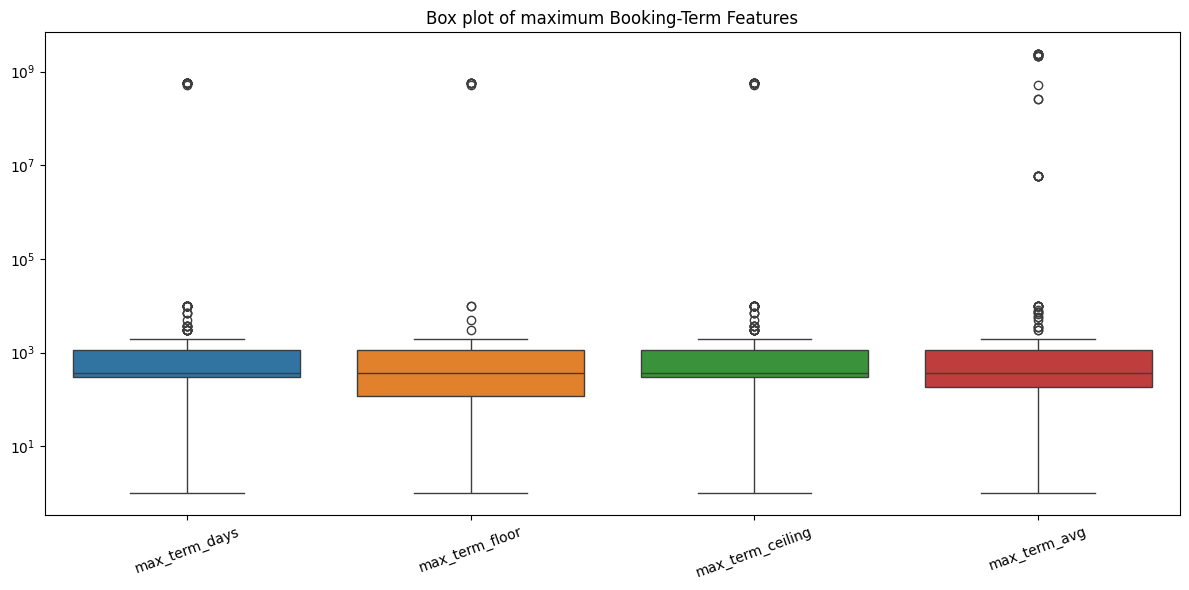

In [8]:
cols = [
    'max_term_days',
    'max_term_floor',
    'max_term_ceiling',
    'max_term_avg'
]

plt.figure(figsize=(12,6))
sns.boxplot(data=train[cols])
plt.yscale('log')
plt.title('Box plot of maximum Booking-Term Features')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 3.6 Duplicate , Invalid and Inconsistent Values

There is no Duplicate rows are there in this data , so we don't have to remove any portion from the data  but it won't tell about that all the values are consistent

In [9]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test:", test.duplicated().sum())

print("Duplicate space_id in train:", train["space_id"].duplicated().sum())
print("Duplicate space_id in test:", test["space_id"].duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in test: 0
Duplicate space_id in train: 0
Duplicate space_id in test: 0


In [10]:

num = train.select_dtypes(include="number")

print(num.describe().round(2))

        space_id  operator_platform_age_years  operator_platform_age_months  \
count  279746.00                    279142.00                     279142.00   
mean   139872.50                         6.79                          5.45   
std     80755.86                         4.19                          3.49   
min         0.00                         0.00                          0.00   
25%     69936.25                         3.00                          2.00   
50%    139872.50                         7.00                          5.00   
75%    209808.75                        10.00                          9.00   
max    279745.00                        17.00                         11.00   

       operator_active_years  operator_active_months  operator_portfolio_size  \
count              279140.00               279140.00                279142.00   
mean                    5.08                    5.30                    49.47   
std                     4.04                 

## 3.7.1 For numerical column

In [11]:
# Check data types and missing values
print(f"\nData Types and Missing Values:")
info_train = pd.DataFrame({
    'Column': train.columns,
    'Non-Null Count': train.count(),
    'Null Count': train.isnull().sum(),
    'Null %': (train.isnull().sum() / len(train) * 100).round(2),
    'Unique Values': train.nunique()
})
print(info_train.to_string(index=False))


Data Types and Missing Values:
                      Column  Non-Null Count  Null Count  Null %  Unique Values
                    space_id          279746           0    0.00         279746
                operator_ref          279142         604    0.22          41903
 operator_platform_age_years          279142         604    0.22             18
operator_platform_age_months          279142         604    0.22             12
       operator_active_years          279140         606    0.22             16
      operator_active_months          279140         606    0.22             12
              operator_class          279746           0    0.00              3
          operator_certified          279142         604    0.22              2
     operator_portfolio_size          279142         604    0.22            328
         operator_has_avatar          279142         604    0.22              2
        operator_id_verified          279142         604    0.22              2
        

## Graph for missing values

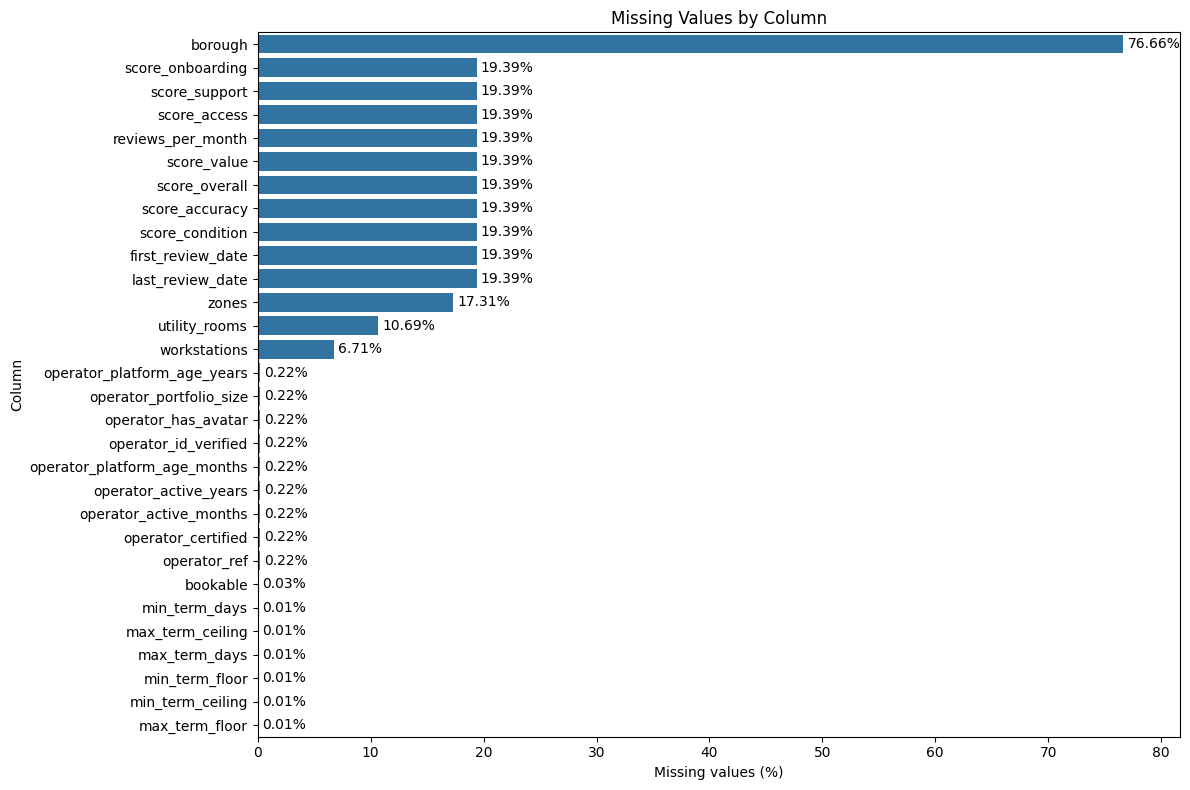

In [12]:
missing = info_train[info_train['Null %'] > 0].sort_values(
    'Null %', ascending= False
)

plt.figure(figsize=(12,8))
ax = sns.barplot(data=missing, x='Null %', y = 'Column')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)
plt.title('Missing Values by Column')
plt.xlabel('Missing values (%)')
plt.xlim(0, missing['Null %'].max() + 5)  # this is for that labels are not cut it off
plt.ylabel('Column')
plt.tight_layout()
plt.show()

According to the missing value analysis reveals that the dataset has varying levels of incomplete information. The borough feature has the highest proportion of missing values 76.66%, followed by review-related features(19.39%). The zones, utility_rooms and workstations features have very low missingness, at approximately 0.22%.
These findings indicate that missing -value treatment should be selected according to the characteristics of each feature rather than applying a single strategy to all columns.

## Outliers

The IQR method identified potential outliers in workspace size, operator portfolio, geographic, booking-term, review, and rating features.

Geographic coordinates need validation because some latitude values fall outside the valid range.

Booking-term and review features may be highly skewed due to differences in booking conditions and workspace popularity.

Availability and operator-experience features have no IQR-detected outliers.

Outliers will not be removed automatically because extreme values may contain useful information for predicting price_tier.

In [13]:
outlier_cols =[]

for col in numerical_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3-Q1


    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    count = ((train[col]< lower)| (train[col]> upper)).sum()

    if count>0:
        outlier_cols.append(col)


    print(f"{col}: {count} potential outlier")

operator_platform_age_years: 0 potential outlier
operator_platform_age_months: 0 potential outlier
operator_active_years: 0 potential outlier
operator_active_months: 0 potential outlier
operator_portfolio_size: 39784 potential outlier
max_seats: 18102 potential outlier
utility_rooms: 18474 potential outlier
zones: 12099 potential outlier
workstations: 5437 potential outlier
min_term_days: 53091 potential outlier
max_term_days: 56 potential outlier
min_term_floor: 53091 potential outlier
min_term_ceiling: 57708 potential outlier
max_term_floor: 11 potential outlier
max_term_ceiling: 56 potential outlier
min_term_avg: 57207 potential outlier
max_term_avg: 41 potential outlier
open_slots_a: 0 potential outlier
open_slots_b: 0 potential outlier
open_slots_c: 0 potential outlier
open_slots_d: 0 potential outlier
review_count: 28455 potential outlier
review_count_12m: 19533 potential outlier
review_count_30d: 38748 potential outlier
open_slots_e: 0 potential outlier
review_count_prev_yr: 277

## Figure for all outlier in one segment

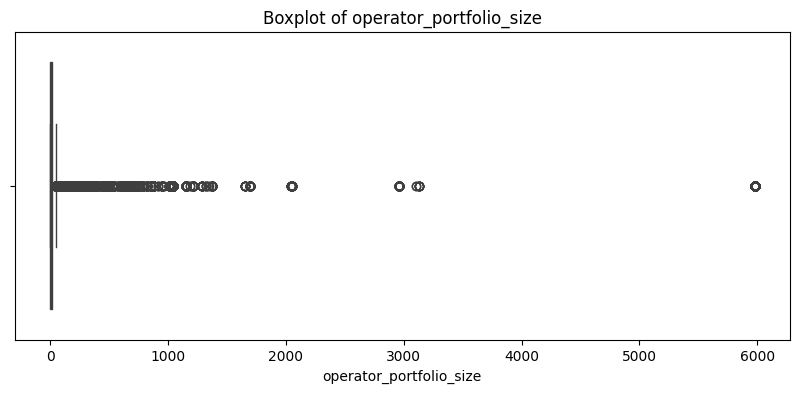

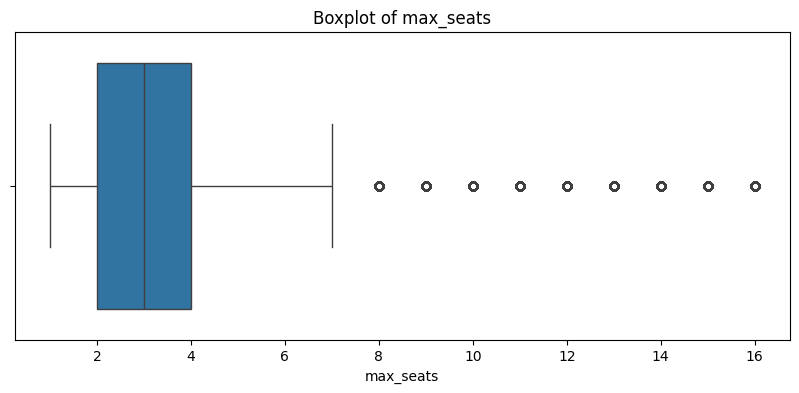

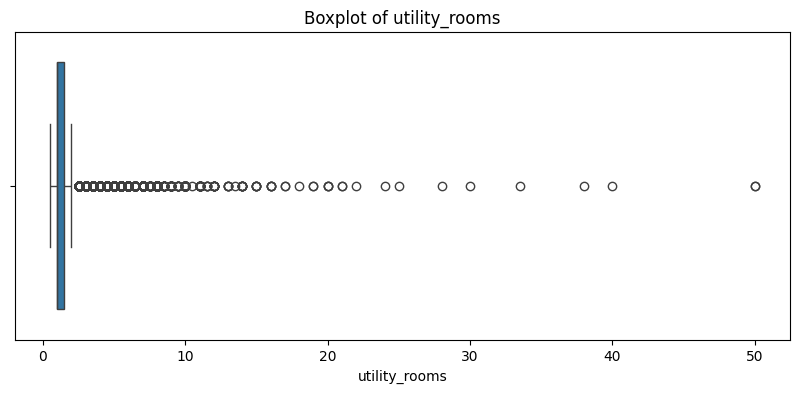

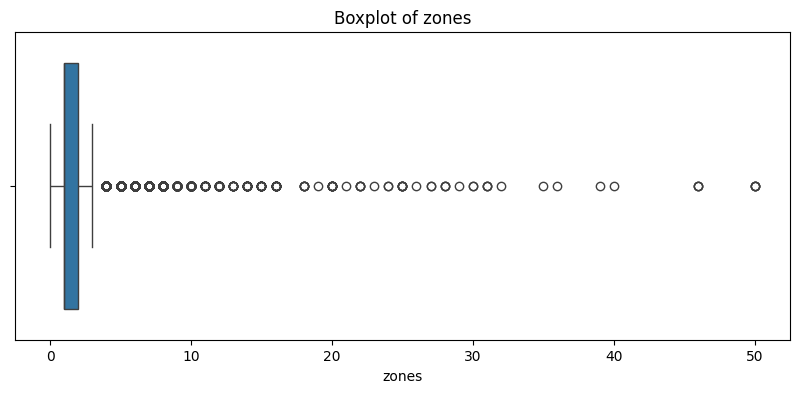

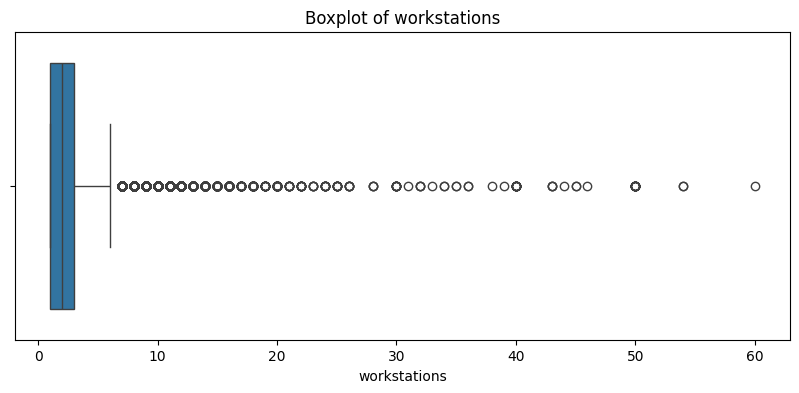

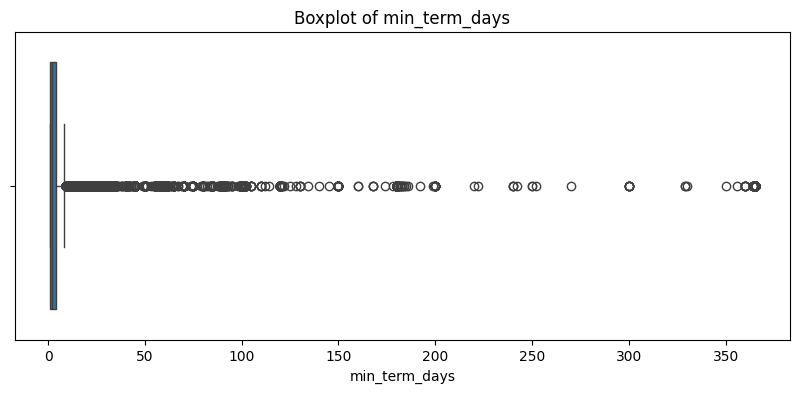

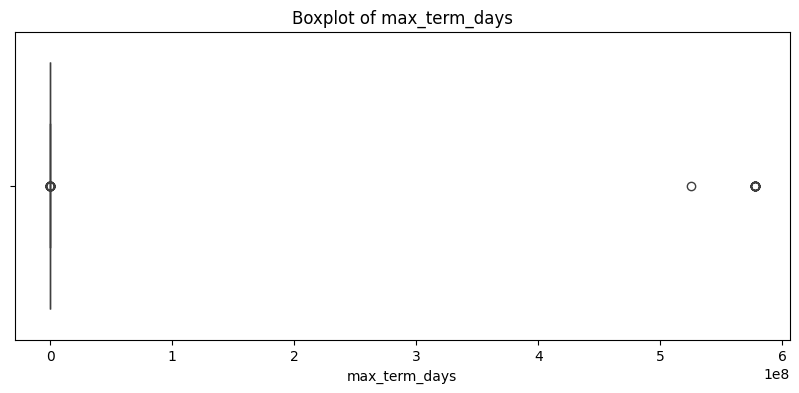

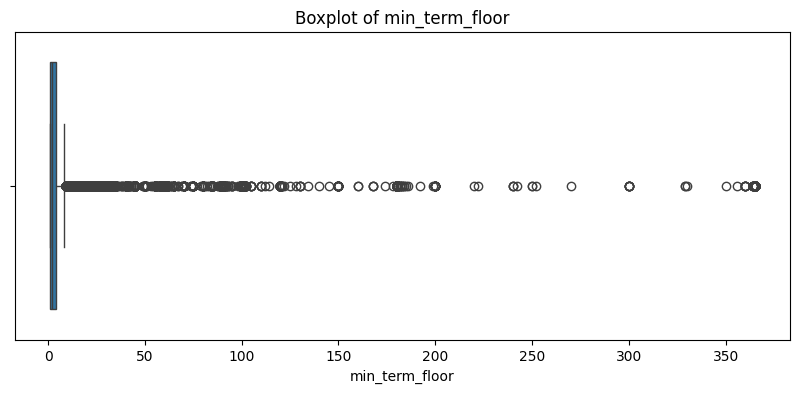

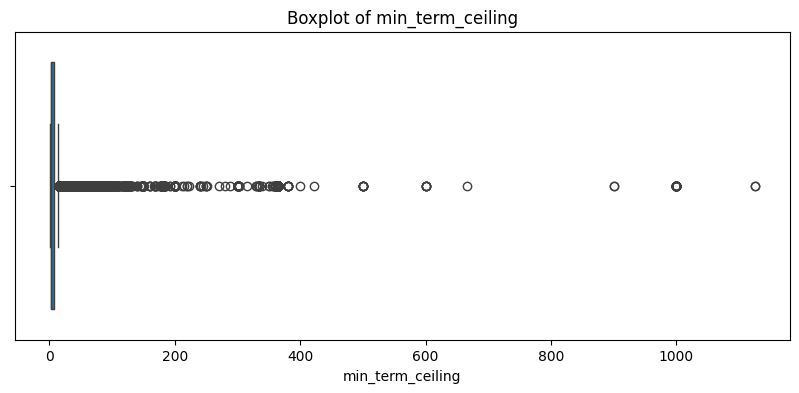

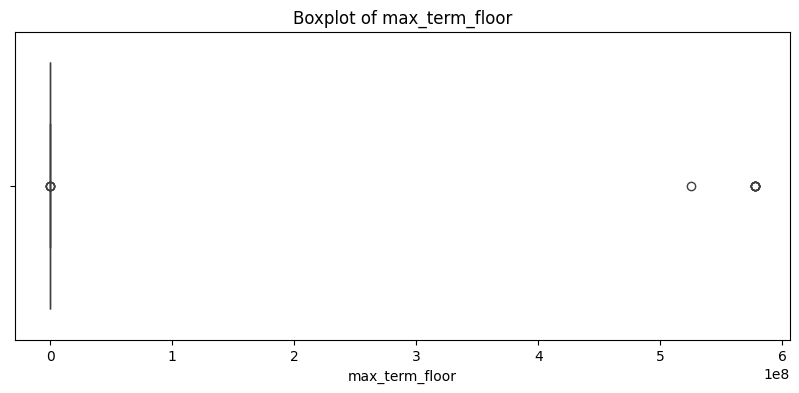

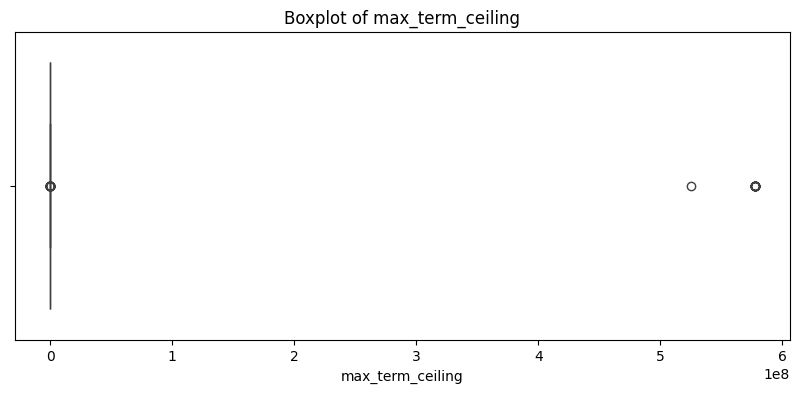

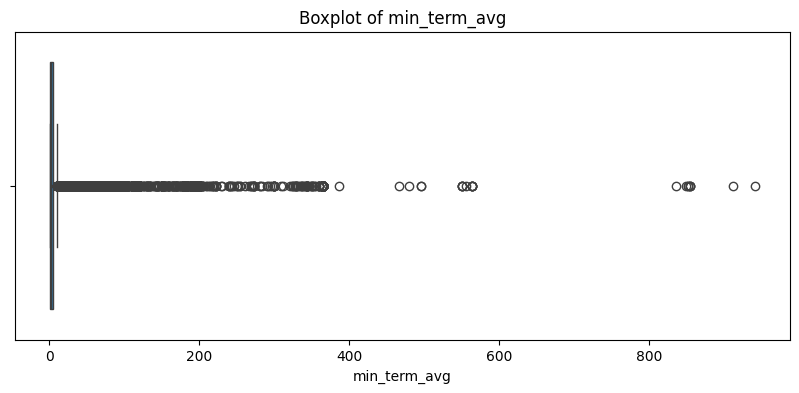

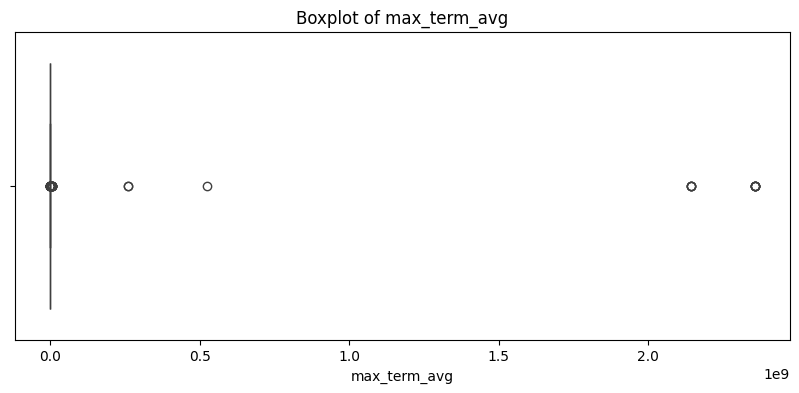

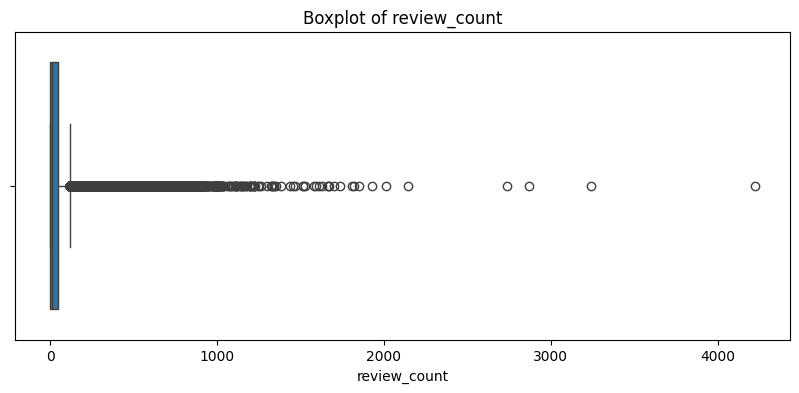

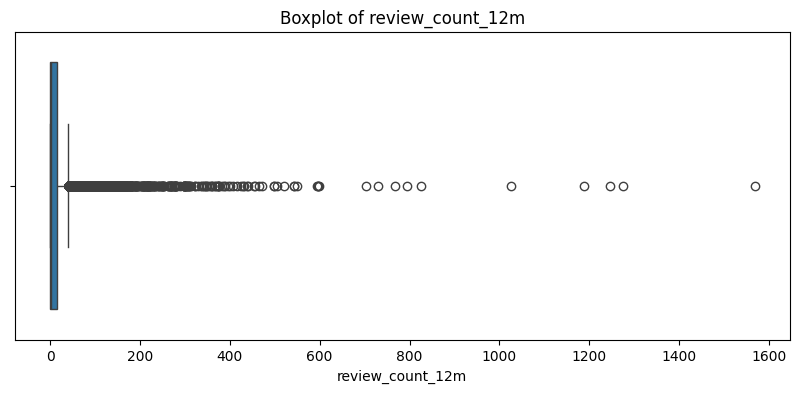

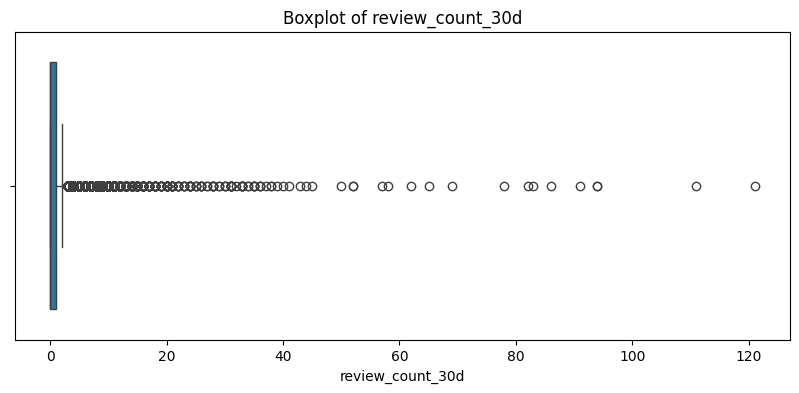

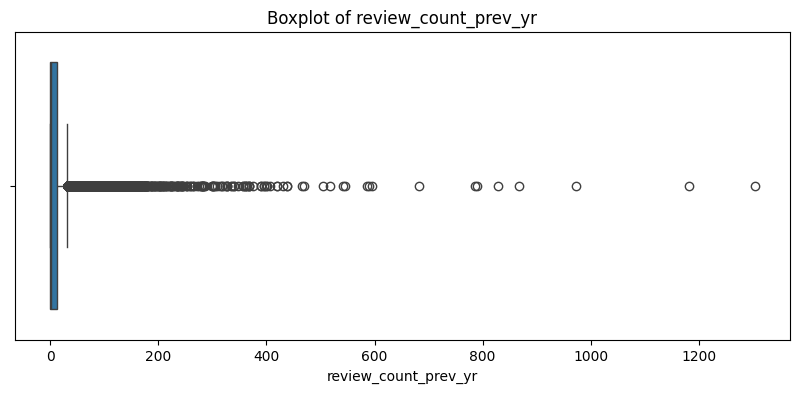

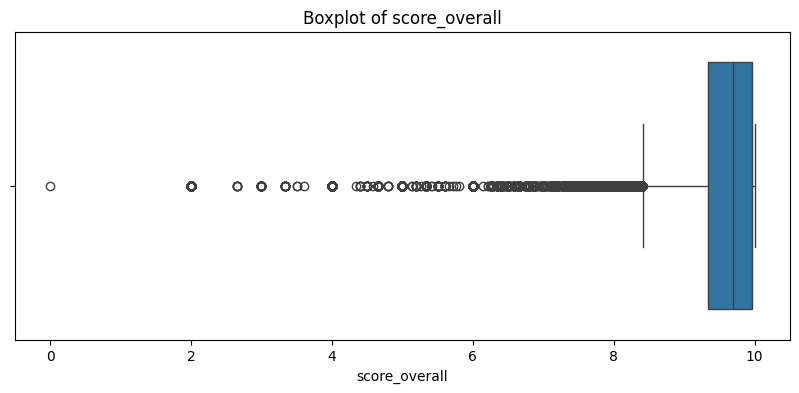

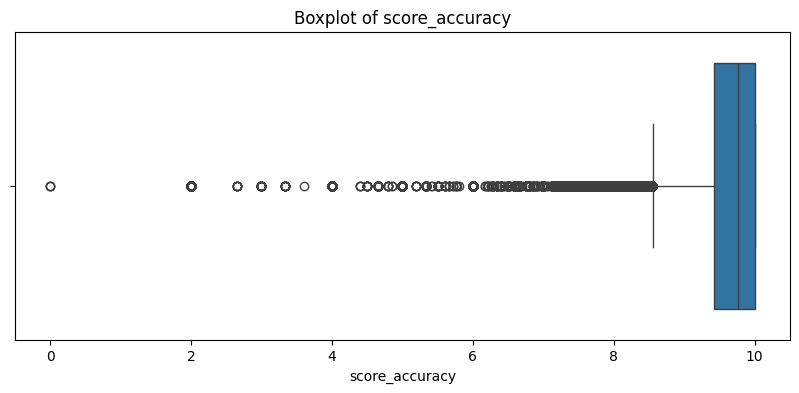

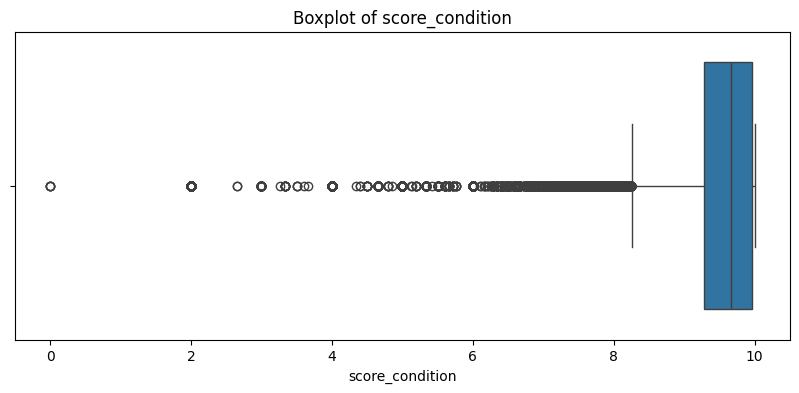

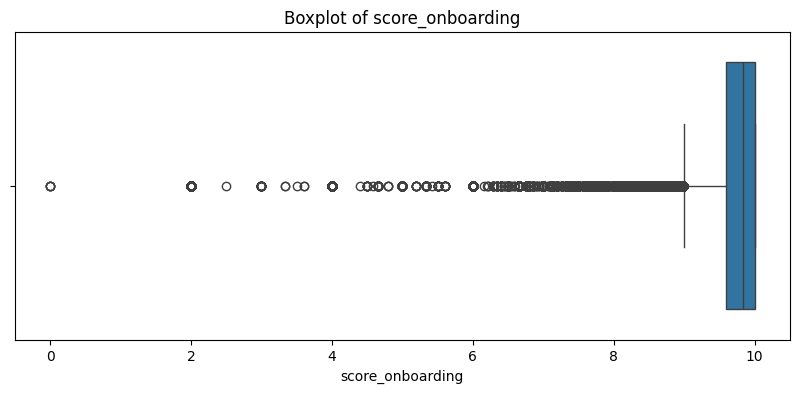

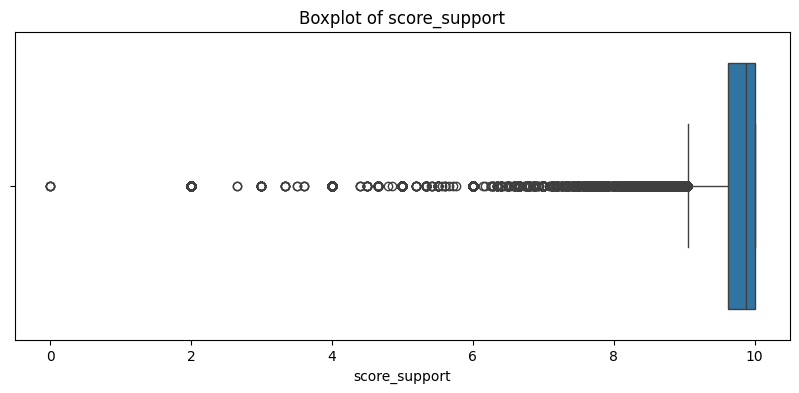

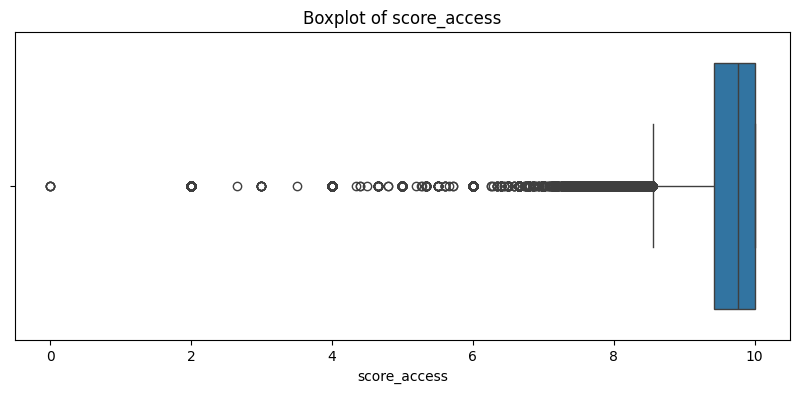

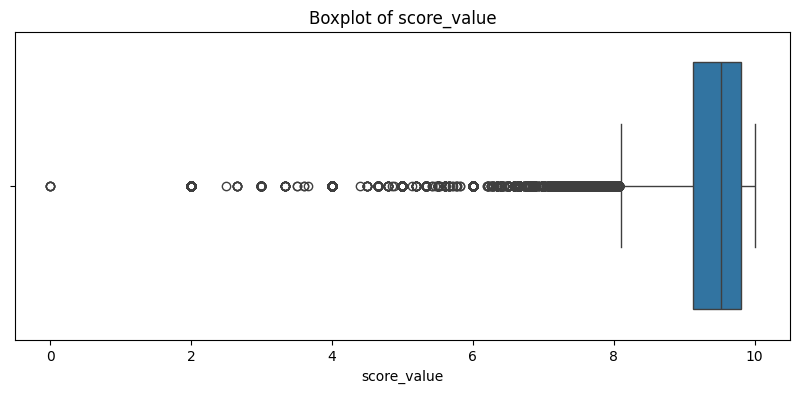

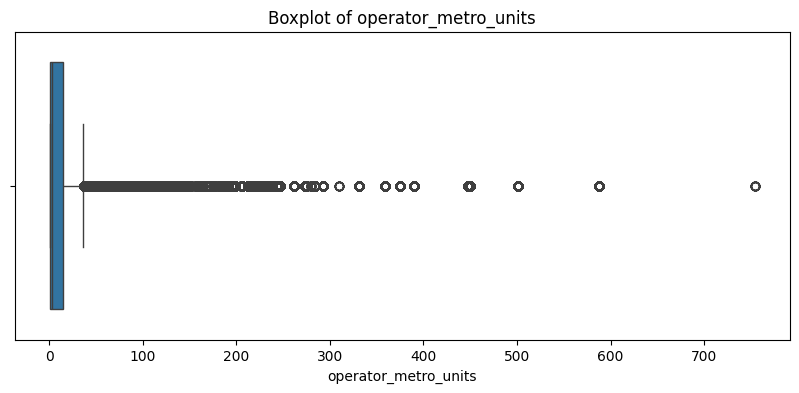

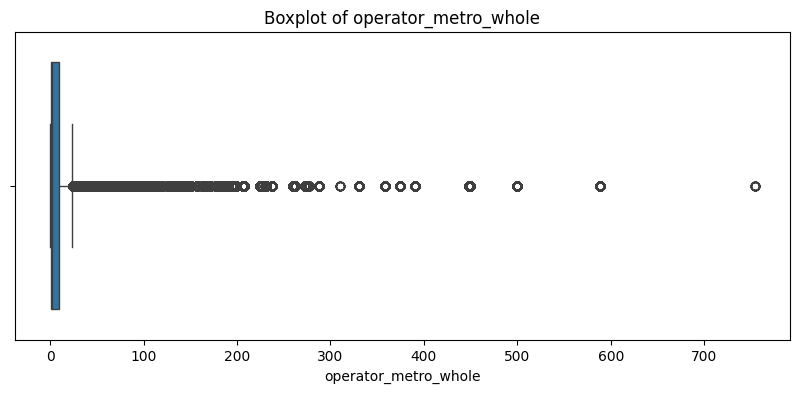

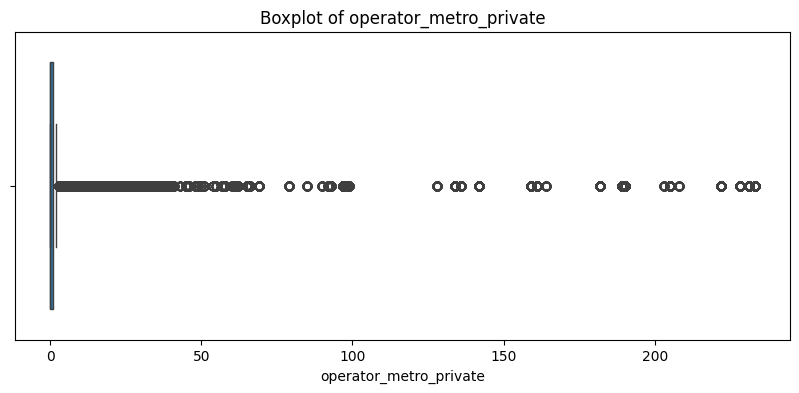

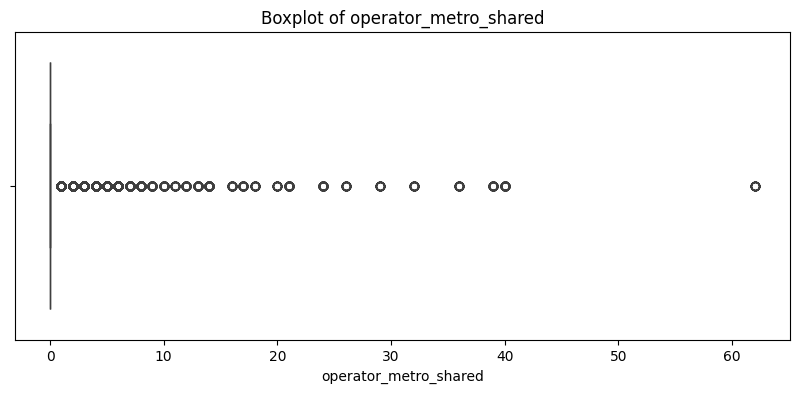

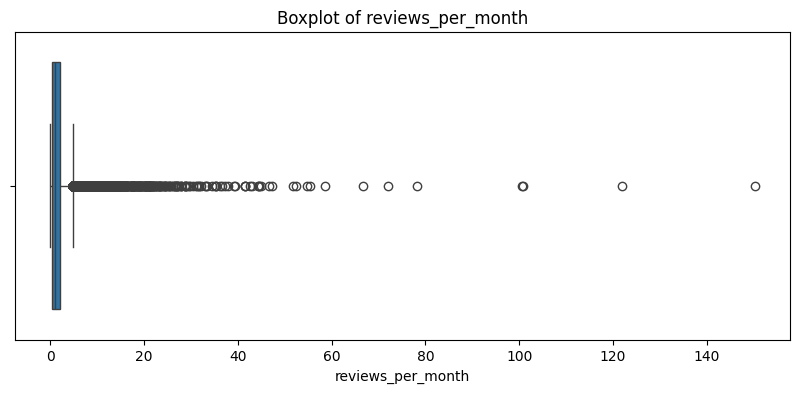

In [14]:
# Plot a separate figure for each column containing potential outliers

for col in outlier_cols:
    plt.figure(figsize=(10, 4))

    sns.boxplot(x=train[col])

    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

## Scaling the numerical column

In [15]:
# Select numerical columns
num_cols = train.select_dtypes(include='number').columns.tolist()

# Remove ID and target columns
num_cols.remove('space_id')
num_cols.remove('price_tier')

# Create scaler and imputer
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

# Fill missing values using training data
train[num_cols] = imputer.fit_transform(train[num_cols])
test[num_cols] = imputer.transform(test[num_cols])

# Scale numerical columns
train[num_cols] = scaler.fit_transform(train[num_cols])
test[num_cols] = scaler.transform(test[num_cols])

print("Numerical scaling completed!")

Numerical scaling completed!


## 3.5 For Categorical column

In [16]:
print(f"\n Categorical Column Summary:")

# select categorical columns
categorical_cols = train.select_dtypes(include=['object','category']).columns.tolist()

#Remove columns that are not usefull as ordinary categorical features
col_to_remove = ['price_tier','space_id']

for col in col_to_remove:
    if col in categorical_cols:
        categorical_cols.remove(col)

# Display the first 5 categorical columns
for col in categorical_cols[:5]:
    unique_count = train[col].nunique()
    unique_values = train[col].dropna().unique()[:10]

    print(f"\n   Column: {col}")
    print(f"   Unique values: {unique_count}")
    print(f"   Examples: {list(unique_values)}")
    print(f"   Missing values: {train[col].isnull().sum()}")


    
# show how many categorical column remain
if len(categorical_cols) > 5:
    print(f"\n   ... and {len(categorical_cols) - 5} more categorical columns")

print(f"\nTotal categorical columns: {len(categorical_cols)}")

print("="*30)
print(f"\n Initial data exploration completed!")
print(f"   • Total workspace records: {train.shape[0]:,}")
print(f"   • Categorical features: {len(categorical_cols)}")
print(f"   • Numerical features: {len(numerical_cols)}")
print(f"   • Missing values across the dataset: {train.isnull().sum().sum():,}")


 Categorical Column Summary:

   Column: operator_ref
   Unique values: 41903
   Examples: ['Bralchu', 'Grorfian', 'Snelenr', 'Spesspe', 'Gosho', 'Harthynrn', 'Vianchessl', 'Sordessx', 'Praless', 'Krafyn']
   Missing values: 604

   Column: operator_class
   Unique values: 3
   Examples: ['independent_operator', 'unverified_operator', 'managed_operator']
   Missing values: 0

   Column: operator_certified
   Unique values: 2
   Examples: ['f', 't']
   Missing values: 604

   Column: operator_has_avatar
   Unique values: 2
   Examples: ['t', 'f']
   Missing values: 604

   Column: operator_id_verified
   Unique values: 2
   Examples: ['t', 'f']
   Missing values: 604

   ... and 12 more categorical columns

Total categorical columns: 17

 Initial data exploration completed!
   • Total workspace records: 279,746
   • Categorical features: 17
   • Numerical features: 39
   • Missing values across the dataset: 325,444


In [17]:
print(type(train))

<class 'pandas.core.frame.DataFrame'>


## Encoding categorical feature

In [18]:
encoder  = OneHotEncoder(
    handle_unknown = 'ignore',
    sparse_output = False
)
train_encoded = encoder.fit_transform(train[categorical_cols])
test_encoded = encoder.transform(test[categorical_cols])

print("Encoded training shape:", train_encoded.shape)
print("Encoded test shape:", test_encoded.shape)


Encoded training shape: (279746, 304557)
Encoded test shape: (114538, 304557)


## Check target variable distribution

In [19]:
print("\nTarget Variable (Price Tier) Distribution:")

tier_counts = train['price_tier'].value_counts().sort_index()
tier_percentages = train['price_tier'].value_counts(normalize=True).sort_index() * 100

for category, count in tier_counts.items():
    percentage = tier_percentages[category]
    print(f"   Tier {category}: {count:,} workspace listings ({percentage:.2f}%)")



Target Variable (Price Tier) Distribution:
   Tier 1: 66,889 workspace listings (23.91%)
   Tier 2: 81,530 workspace listings (29.14%)
   Tier 3: 60,839 workspace listings (21.75%)
   Tier 4: 70,488 workspace listings (25.20%)


### Insights: Target Variable Distribution (`price_tier`)

1. The target variable `price_tier` contains four categories: Tier 1, Tier 2, Tier 3, and Tier 4.

2. **Tier 2** has the highest number of workspace listings, with 81,530 records (29.14%).

3. **Tier 3** has the lowest number of workspace listings, with 60,839 records (21.75%).

4. Tier 1 accounts for 23.91% of listings, while Tier 4 accounts for 25.20%.

5. The target classes are relatively balanced, as each class represents approximately 22%–29% of the dataset. Therefore, there is no severe class imbalance.

6. Since the evaluation metric is Macro F1, the model should aim to predict all four classes effectively rather than performing well only on the most frequent class.

## For imbalance class

In [20]:
# Calculate class imbalance ratio
tier_counts = train['price_tier'].value_counts()

minority_class = tier_counts.min()
majority_class = tier_counts.max()

imbalance_ratio = majority_class / minority_class

print(f"   Class imbalance ratio: {imbalance_ratio:.1f}:1")

if imbalance_ratio > 3:
    print("    Significant class imbalance detected - special handling may be needed")
else:
    print("    Mild class imbalance - standard techniques should work")

   Class imbalance ratio: 1.3:1
    Mild class imbalance - standard techniques should work


- The dataset contains four price tiers.
- Tier 2 has the most listings (29.14%), while Tier 3 has the fewest (21.75%).
- The imbalance ratio is 1.34:1, indicating that the classes are relatively balanced.
- No special balancing technique is needed at this stage.

## Model building 